# Phase 2 — Exploratory Data Analysis & Preprocessing

**Project:** A Data-Driven Crop Recommendation Web Application Using Machine Learning
**Notebook:** `notebooks/eda.ipynb`  ·  **Data:** `data/original_dataset.csv`

### Objectives (from `docs/plan.md`, Phase 2)
1. Load the data and check it against the data dictionary.
2. Assess data quality: types, missing values, duplicates, label conflicts, dirty categories.
3. Understand each feature (univariate) and detect outliers.
4. Study relationships between features and the target crop (bivariate / multivariate).
5. Evaluate candidate engineered features.
6. Design and validate a leakage-safe preprocessing pipeline (imputation, scaling, encoding).
7. Save clean, split data for Phase 3 and record all decisions.

### Notebook map
| § | Section |
|---|---|
| 1 | Setup |
| 2 | Load data & schema check |
| 3 | Data quality: missing values, categories, duplicates |
| 4 | Univariate analysis |
| 5 | Outlier detection |
| 6 | Bivariate & multivariate analysis |
| 7 | Feature engineering (candidates, evaluated) |
| 8 | Preprocessing pipeline: split, impute, scale, encode |
| 9 | Save outputs |
| 10 | Summary of findings & decisions |

> Rule from `docs/workflow.md`: `data/` is read-only. Every cleaning step below is done in code;
> the raw CSV is never edited.

## 1. Setup
Imports, paths, a single global random seed (`RANDOM_STATE = 42`) for reproducibility, and a folder
for saved figures (`reports/figures/`).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

# Paths are resolved relative to the project root so the notebook runs from notebooks/ or the root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
RAW_PATH = DATA_DIR / "original_dataset.csv"
DICT_PATH = DATA_DIR / "data_dictionary.csv"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC_FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
CATEGORICAL_FEATURES = ["soil"]
TARGET = "crop_label"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)

def save_fig(fig, name: str) -> None:
    # Save a figure to reports/figures/ so results can be reviewed outside the notebook.
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

print("Project root:", PROJECT_ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

Project root: /home/iyasir/Workspace/Crop Recomendation System
pandas 3.1.1 | numpy 2.5.5


## 2. Load data & schema check
We load the raw CSV and the data dictionary, then confirm every documented column exists.
Phase 1 noted that the dictionary names the soil column `soil_texture` while the CSV calls it `soil`;
we treat these as aliases and keep the CSV name.

In [2]:
raw = pd.read_csv(RAW_PATH)
data_dict = pd.read_csv(DICT_PATH)

print("Raw shape:", raw.shape)
display(raw.head())
display(data_dict)

Raw shape: (5000, 9)


,N,P,K,temperature,humidity,ph,rainfall,soil,crop_label
0,40,27,45,21.66,94.79,5.89,112.43,sandy loam,guinea_corn
1,120,7,47,24.25,83.04,6.65,54.77,loamy clay,pepper
2,102,11,47,27.99,92.78,6.50,27.15,sandy loam,tomatoes
3,5,25,6,30.72,94.01,6.01,106.81,loamy,orange
4,36,43,21,28.36,84.86,7.14,52.93,loamy,yam


,Column Name,Description,Data Type,Example Value
0,N,Nitrogen content in soil (essential macronutri...,float,90
1,P,Phosphorus content in soil (supports root deve...,float,42
2,K,Potassium content in soil (improves plant resi...,float,43
3,temperature,Ambient temperature (°C) affecting crop growth...,float,26.5
4,humidity,Relative humidity (%) of the environment,float,80
5,ph,Soil pH level indicating acidity or alkalinity...,float,6.5
6,rainfall,Annual or seasonal rainfall (mm),float,120
7,soil_texture,Categorical soil type describing soil composit...,categorical,loamy
8,crop_label,Target crop class label representing recommend...,string / categorical,maize


In [3]:
COLUMN_ALIASES = {"soil_texture": "soil"}  # data dictionary name -> CSV name

documented = [COLUMN_ALIASES.get(c, c) for c in data_dict["Column Name"]]
missing_cols = set(documented) - set(raw.columns)
extra_cols = set(raw.columns) - set(documented)
print("Documented columns missing from CSV:", missing_cols or "none")
print("CSV columns not in dictionary:   ", extra_cols or "none")
assert not missing_cols and not extra_cols, "Schema mismatch with data dictionary"

print("\nData types:")
print(raw.dtypes)

Documented columns missing from CSV: none
CSV columns not in dictionary:    none

Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
soil               str
crop_label         str
dtype: object


**Result:** all 9 documented columns are present (with the `soil_texture` → `soil` alias). The 7 numeric
features are read as numbers, and `soil` and `crop_label` are strings.

## 3. Data quality
### 3.1 Missing values
We check for nulls and for blank strings, which pandas does not count as null.

In [4]:
null_counts = raw.isna().sum()
blank_counts = raw.select_dtypes(include=["object", "string"]).apply(lambda s: s.str.strip().eq("").sum())
quality = pd.DataFrame({"nulls": null_counts, "blank_strings": blank_counts}).fillna(0).astype(int)
display(quality)
print("Total missing cells:", int(quality.values.sum()))

,nulls,blank_strings
K,0,0
N,0,0
P,0,0
crop_label,0,0
humidity,0,0
ph,0,0
rainfall,0,0
soil,0,0
temperature,0,0


Total missing cells: 0


**Result:** there are no missing values. The production pipeline (§8) still includes imputers
(median for numerics, most frequent for soil). That way a blank value at inference time, for example a field
the report parser could not find, is handled safely instead of crashing. Imputers are fitted on training data only.

### 3.2 Categorical clean-up
Category strings may differ only in whitespace or case, so we normalise them by stripping spaces and lower-casing.

In [5]:
print("Raw soil values:", raw["soil"].map(repr).unique().tolist())
print("Raw crop values:", sorted(raw["crop_label"].map(repr).unique().tolist()))

def clean_categories(df: pd.DataFrame) -> pd.DataFrame:
    # Strip whitespace and lower-case all string columns. Returns a copy.
    out = df.copy()
    for col in out.select_dtypes(include=["object", "string"]).columns:
        out[col] = out[col].str.strip().str.lower()
    return out

df = clean_categories(raw)
print("\nClean soil values:", sorted(df["soil"].unique()))
print("Clean crop values:", sorted(df[TARGET].unique()))

Raw soil values: ["'sandy loam'", "'loamy clay '", "'loamy'", "'clay'"]
Raw crop values: ["'beans'", "'cassava'", "'guinea_corn'", "'maize'", "'orange'", "'pepper'", "'rice'", "'soybean'", "'tomatoes'", "'yam'"]

Clean soil values: ['clay', 'loamy', 'loamy clay', 'sandy loam']
Clean crop values: ['beans', 'cassava', 'guinea_corn', 'maize', 'orange', 'pepper', 'rice', 'soybean', 'tomatoes', 'yam']


**Result:** `"loamy clay "` had a trailing space and is now `"loamy clay"`. There are 4 soil types and 10 crops.

### 3.3 Duplicates and label conflicts
Phase 1 found heavy exact duplication. Duplicates matter for two reasons:
- If copies of the same row land in both the train and test sets, test scores are inflated (**data leakage**).
- Duplicates distort the apparent class balance.

We also check for **label conflicts**, meaning identical features with a different crop.

In [6]:
n_total = len(df)
n_unique = len(df.drop_duplicates())
print(f"Rows: {n_total}  |  unique rows: {n_unique}  |  exact duplicates: {n_total - n_unique}")

copies = df.value_counts().rename("copies")
print("\nHow many times each unique row appears:")
print(copies.describe()[["min", "50%", "mean", "max"]])

feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES
conflicts = df.groupby(feature_cols)[TARGET].nunique()
print("\nFeature rows mapped to more than one crop (label conflicts):", int((conflicts > 1).sum()))

Rows: 5000  |  unique rows: 1000  |  exact duplicates: 4000

How many times each unique row appears:
min      1.0
50%      4.0
mean     5.0
max     23.0
Name: copies, dtype: float64

Feature rows mapped to more than one crop (label conflicts): 0


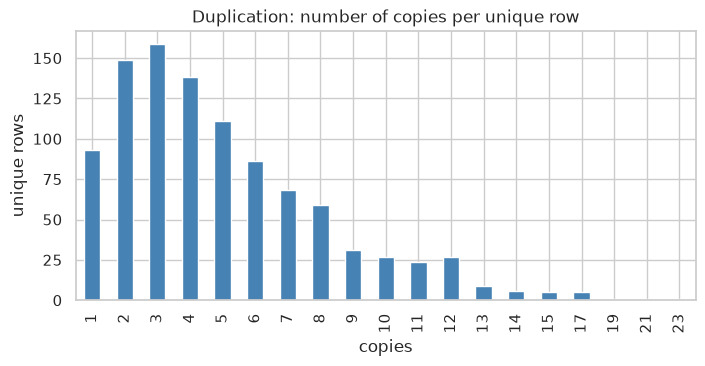

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
copies.value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set(title="Duplication: number of copies per unique row", xlabel="copies", ylabel="unique rows")
save_fig(fig, "01_duplication")
plt.show()

,raw_rows,unique_rows
crop_label,,
soybean,587,100
beans,584,100
guinea_corn,561,100
pepper,538,100
orange,507,100
tomatoes,491,100
yam,486,100
maize,485,100
rice,462,100


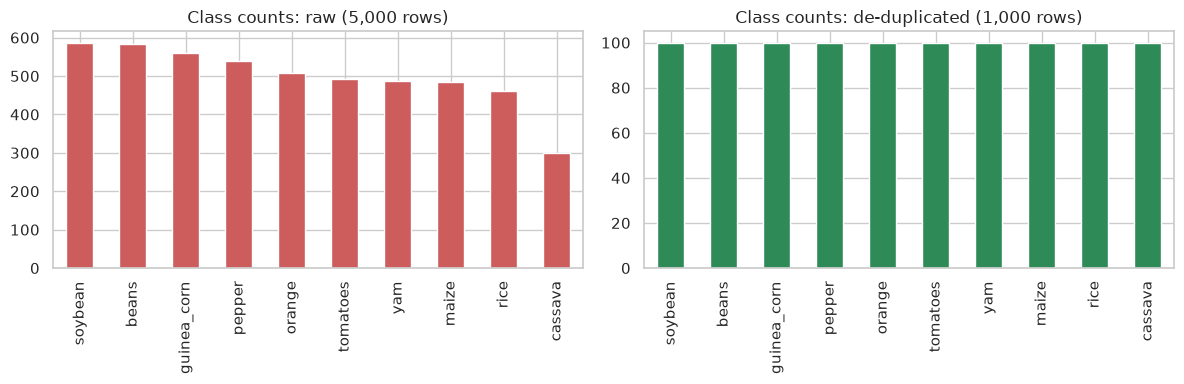

In [8]:
df_clean = df.drop_duplicates().reset_index(drop=True)

balance = pd.DataFrame({
    "raw_rows": df[TARGET].value_counts(),
    "unique_rows": df_clean[TARGET].value_counts(),
}).sort_values("raw_rows", ascending=False)
display(balance)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
balance["raw_rows"].plot(kind="bar", ax=axes[0], color="indianred", title="Class counts: raw (5,000 rows)")
balance["unique_rows"].plot(kind="bar", ax=axes[1], color="seagreen", title="Class counts: de-duplicated (1,000 rows)")
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
save_fig(fig, "02_class_balance")
plt.show()

**Result and decision:**
- Only **1,000 of the 5,000 rows are unique**. Each unique row appears between 1 and 23 times.
- There are **no label conflicts**, so every unique feature row maps to exactly one crop.
- The raw class imbalance (cassava 299 vs soybean 587) comes **entirely from duplication**. After
  de-duplication every crop has exactly **100 rows**, so no resampling or class weighting is needed.
- **Decision:** we de-duplicate *before* any split. All remaining analysis uses `df_clean` (1,000 rows).

## 4. Univariate analysis
Summary statistics, skewness and distributions for each numeric feature, plus soil-type counts.

In [9]:
summary = df_clean[NUMERIC_FEATURES].describe().T
summary["skew"] = df_clean[NUMERIC_FEATURES].skew()
summary["kurtosis"] = df_clean[NUMERIC_FEATURES].kurt()
display(summary)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
N,1000.0,51.77,34.42,0.00,23.00,40.00,83.00,120.00,0.33,-1.19
P,1000.0,41.61,22.46,5.00,21.00,44.00,60.00,80.00,-0.02,-1.31
K,1000.0,34.93,20.46,5.00,18.00,30.00,47.00,85.00,0.81,-0.10
temperature,1000.0,24.24,4.66,10.01,20.32,24.69,27.94,34.95,-0.20,-0.35
humidity,1000.0,69.62,27.04,14.26,61.89,82.71,89.95,95.00,-1.10,-0.35
ph,1000.0,6.58,0.64,5.01,6.12,6.54,6.97,8.87,0.48,0.27
rainfall,1000.0,91.67,57.27,20.21,55.95,78.11,108.57,298.56,1.65,2.76


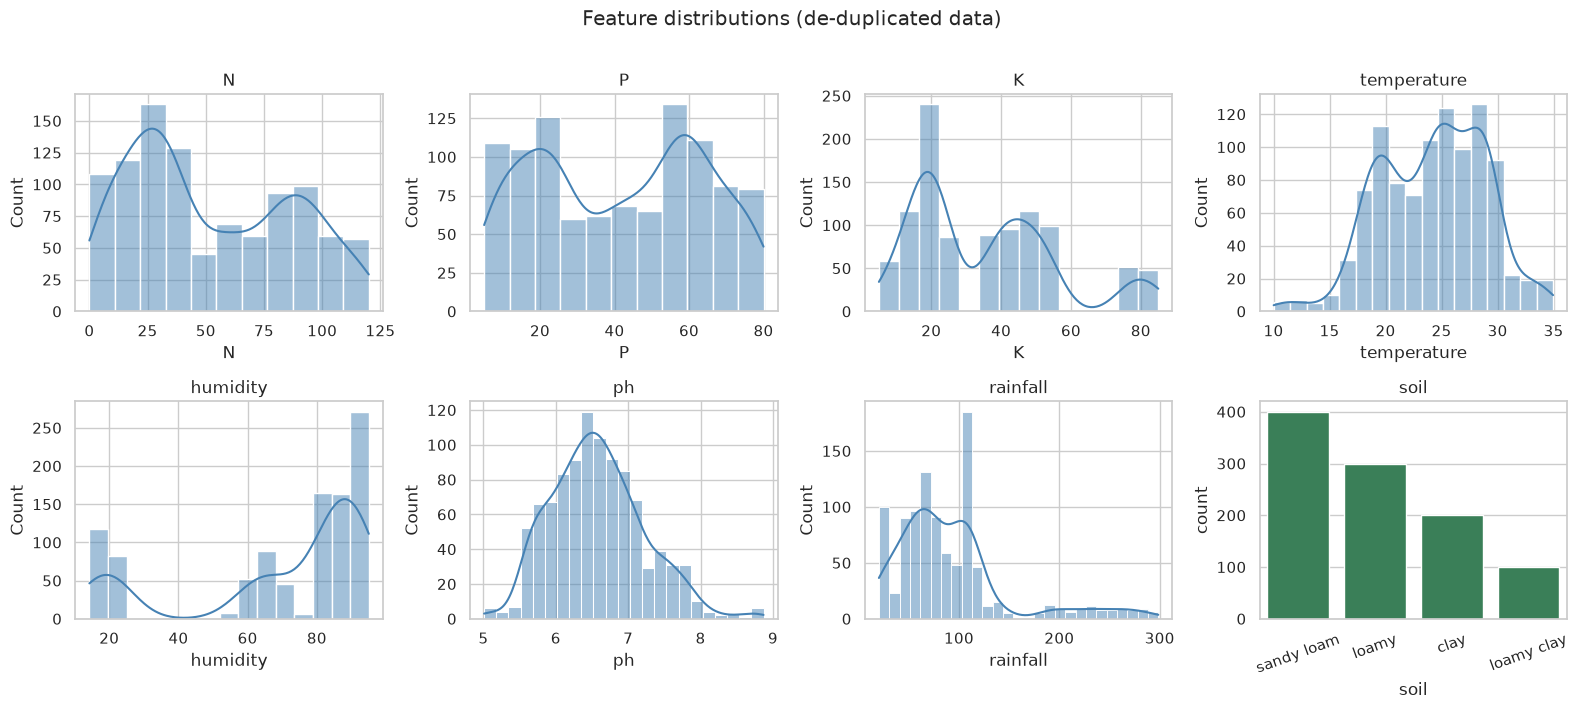

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(df_clean[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
sns.countplot(data=df_clean, x="soil", ax=axes.flat[-1], color="seagreen",
              order=df_clean["soil"].value_counts().index)
axes.flat[-1].set_title("soil")
axes.flat[-1].tick_params(axis="x", rotation=20)
fig.suptitle("Feature distributions (de-duplicated data)", y=1.01)
fig.tight_layout()
save_fig(fig, "03_distributions")
plt.show()

**Observations** (from the table and plots above):
- The features sit on very different scales, from pH at about 5 to 9 up to rainfall at about 20 to 300 mm.
  Distance- and margin-based models (SVM, KNN, Logistic Regression) need **scaling**.
- Several distributions are **multi-modal**, with different crops clustering in different value bands. This
  is a good sign that the features separate the classes.
- The soil type is uneven: sandy loam 400, loamy 300, clay 200, loamy clay 100.

## 5. Outlier detection
We use two standard methods per numeric feature:
- **IQR rule:** a value is flagged if it lies outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR].
- **Z-score:** a value is flagged if |z| > 3.

We then look at the values per crop. A value that looks extreme across the whole dataset can be completely
normal for one crop (rice needs high rainfall, for example).

In [11]:
def outlier_report(data: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    # Count IQR and z-score outliers per column and report the IQR fences.
    rows = []
    for col in cols:
        s = data[col]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        z = np.abs(stats.zscore(s))
        rows.append({
            "feature": col, "min": s.min(), "max": s.max(),
            "iqr_low": lo, "iqr_high": hi,
            "iqr_outliers": int(((s < lo) | (s > hi)).sum()),
            "z>3_outliers": int((z > 3).sum()),
        })
    return pd.DataFrame(rows).set_index("feature")

global_outliers = outlier_report(df_clean, NUMERIC_FEATURES)
display(global_outliers)

,min,max,iqr_low,iqr_high,iqr_outliers,z>3_outliers
feature,,,,,,
N,0.00,120.00,-67.00,173.00,0,0
P,5.00,80.00,-37.50,118.50,0,0
K,5.00,85.00,-25.50,90.50,0,0
temperature,10.01,34.95,8.91,39.36,0,3
humidity,14.26,95.00,19.80,132.04,122,0
ph,5.01,8.87,4.85,8.24,11,8
rainfall,20.21,298.56,-22.98,187.51,91,27


In [12]:
# Per-crop view: count IQR outliers computed *within* each crop.
def per_group_iqr_outliers(data, cols, group):
    def count(g):
        q1, q3 = g[cols].quantile(0.25), g[cols].quantile(0.75)
        iqr = q3 - q1
        return ((g[cols] < q1 - 1.5 * iqr) | (g[cols] > q3 + 1.5 * iqr)).sum()
    return data.groupby(group)[cols].apply(count)

within_crop = per_group_iqr_outliers(df_clean, NUMERIC_FEATURES, TARGET)
display(within_crop)
print("Total within-crop IQR flags:", int(within_crop.values.sum()), "of", df_clean[NUMERIC_FEATURES].size, "values")

,N,P,K,temperature,humidity,ph,rainfall
crop_label,,,,,,,
beans,0,0,0,0,0,0,0
cassava,0,0,0,0,0,0,0
guinea_corn,0,0,0,0,0,0,0
maize,0,0,0,0,0,0,0
orange,0,0,0,0,0,0,0
pepper,0,0,0,0,0,0,0
rice,0,0,0,0,0,0,0
soybean,0,0,0,0,0,0,0
tomatoes,0,0,0,0,0,0,0


Total within-crop IQR flags: 0 of 7000 values


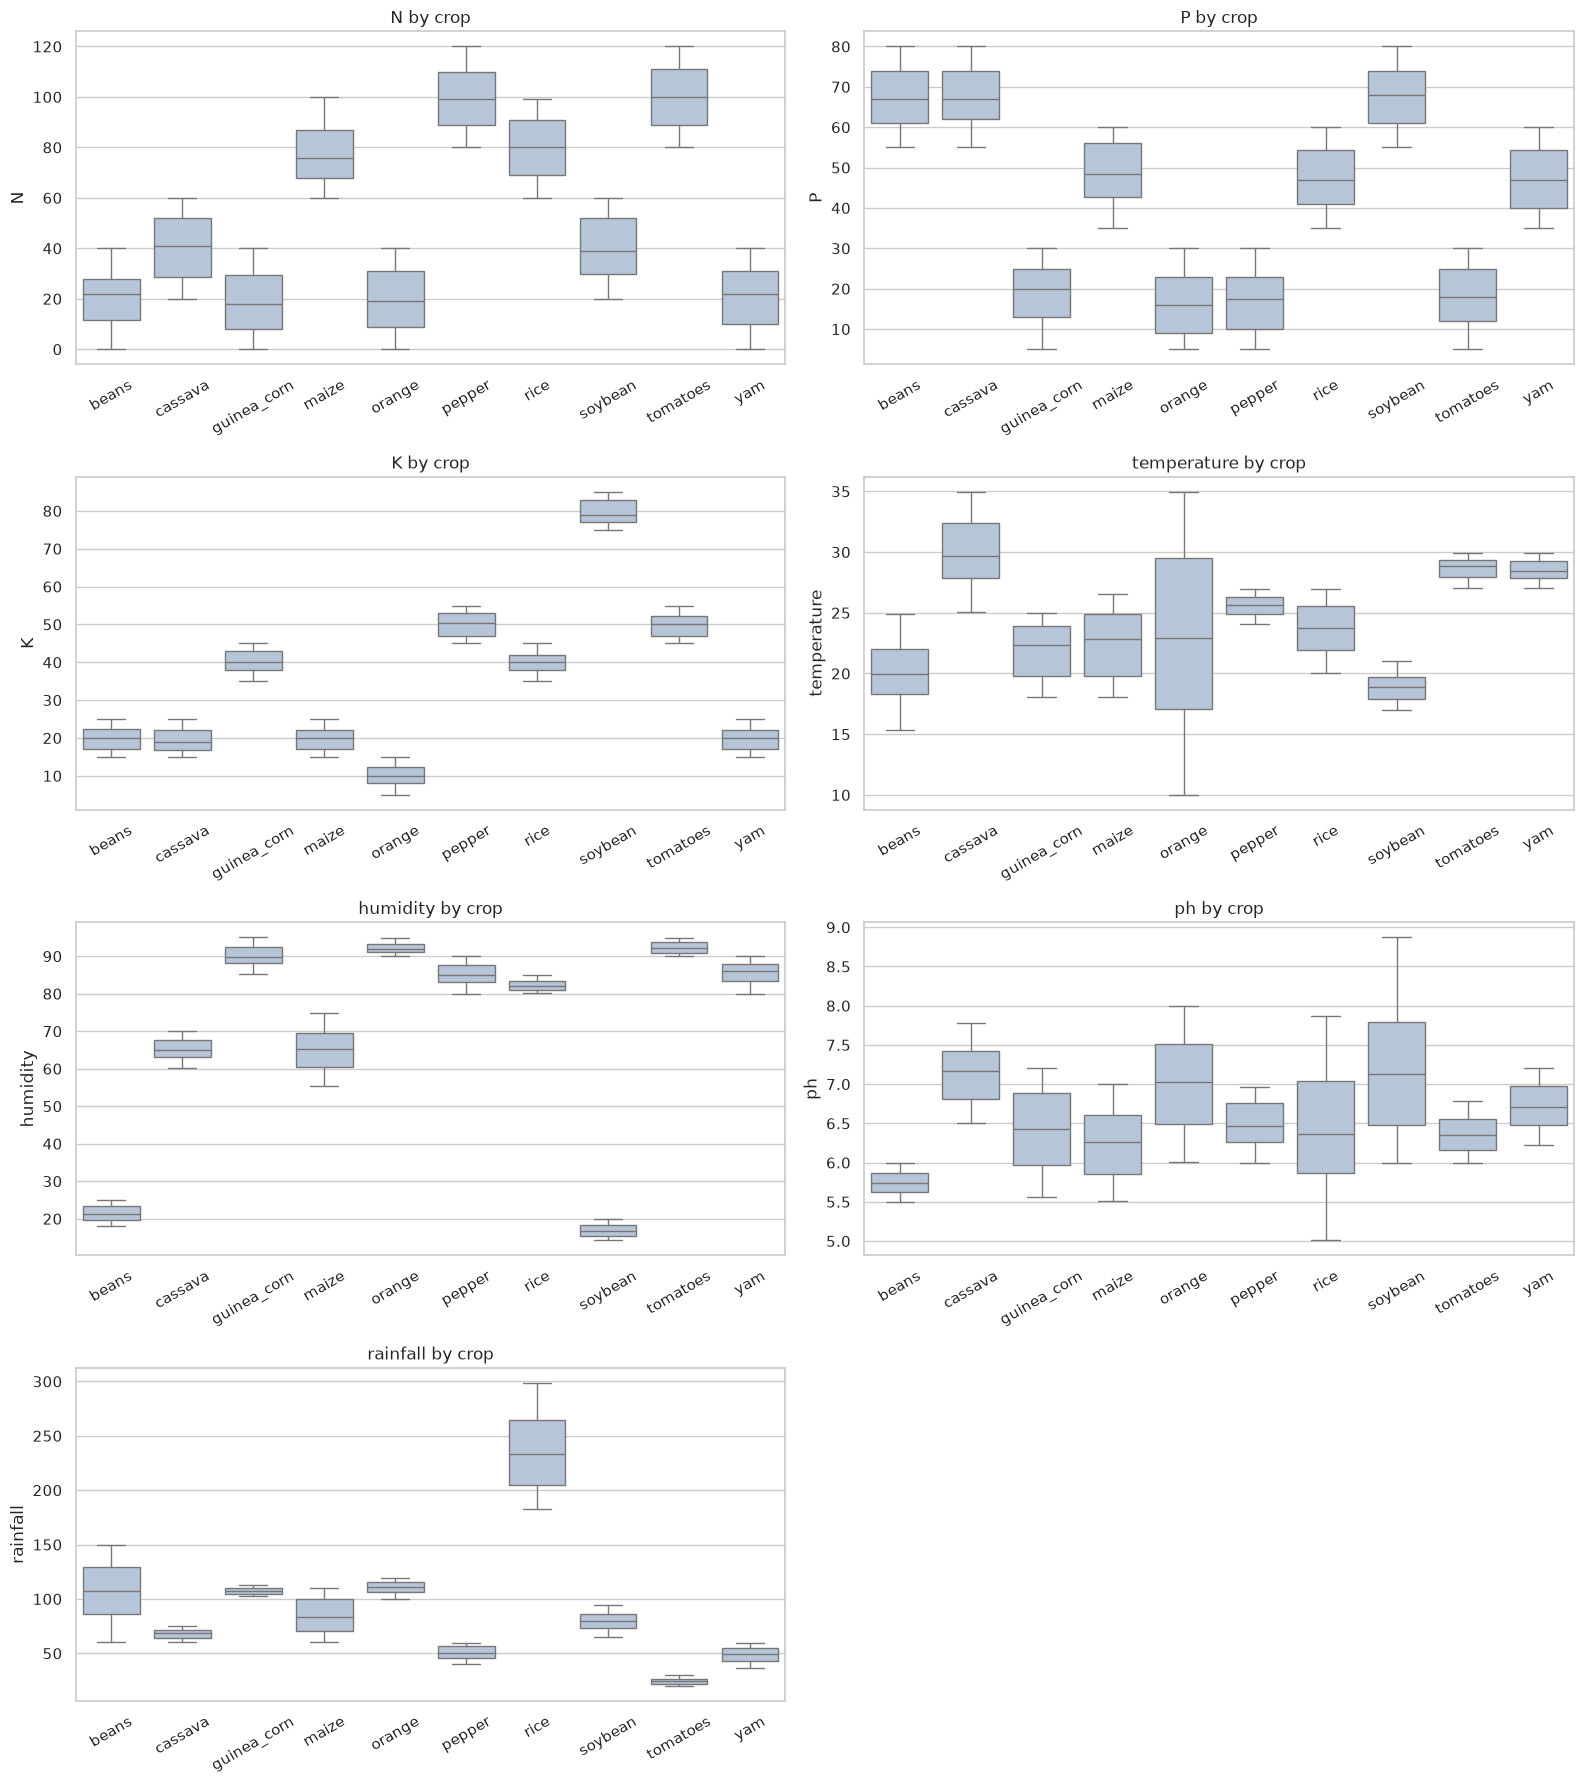

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
crop_order = sorted(df_clean[TARGET].unique())
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.boxplot(data=df_clean, x=TARGET, y=col, order=crop_order, ax=ax, color="lightsteelblue")
    ax.set_title(f"{col} by crop")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes.flat[-1].axis("off")
fig.tight_layout()
save_fig(fig, "04_boxplots_by_crop")
plt.show()

**Results:** across the whole dataset, IQR flags appear only for humidity (122), rainfall (91) and pH (11),
plus a handful of |z| > 3 values. **Within each crop there are zero IQR outliers** (0 of 7,000 values). Every
globally flagged value is typical for its own crop, for example the high rainfall of rice (mean about 236 mm) or the
low humidity of beans and soybean (about 17 to 22 %).

**Decision on outliers: keep and document, no removal or capping.**
- Every value lies within agronomically plausible ranges (§2 of `docs/project_overview.md`): N 0 to 120,
  pH about 5 to 8.9, rainfall about 20 to 300 mm. None looks like a data-entry error.
- Values flagged across the whole dataset mostly belong to specific crops, as the box plots show. They are
  **signal, not noise**, and removing them would delete the very rows that identify those crops.
- With only 100 rows per class, dropping rows is costly.
- Robustness: the tree models (RF, GBM, XGBoost, LightGBM) are insensitive to extreme values. For linear and
  SVM models, standard scaling is enough, and Phase 3 can compare `RobustScaler` if needed.
- At inference time, inputs outside the training range will trigger a **warning** in the app rather than
  being rejected (`docs/workflow.md` §3).

## 6. Bivariate & multivariate analysis
### 6.1 Correlation between numeric features

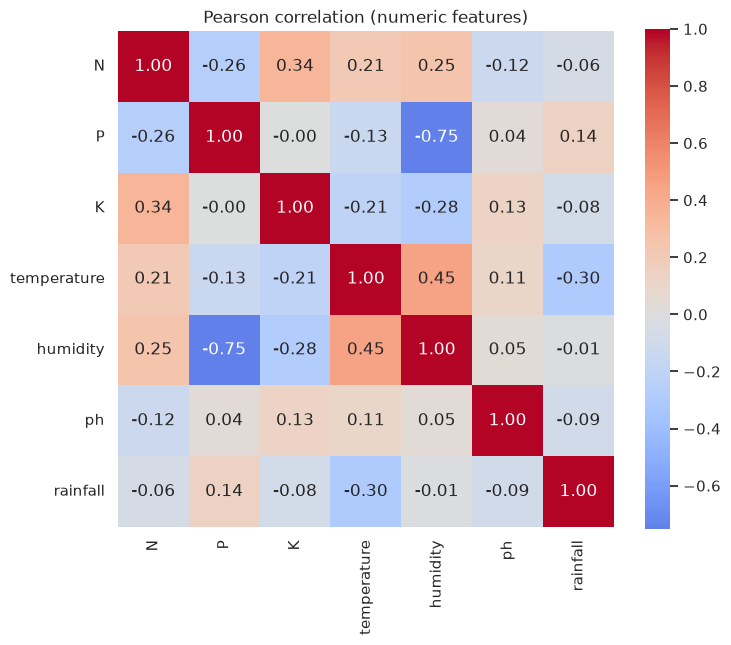

Strongest pairwise |correlations|:
P            humidity    0.75
temperature  humidity    0.45
N            K           0.34
temperature  rainfall    0.30
K            humidity    0.28
dtype: float64


In [14]:
corr = df_clean[NUMERIC_FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Pearson correlation (numeric features)")
save_fig(fig, "05_correlation")
plt.show()

high = (corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False))
print("Strongest pairwise |correlations|:")
print(high.head(5).round(3))

**Result:** the strongest pair is P–humidity (r = 0.75), followed by temperature–humidity (0.45). No pair exceeds
the 0.8 redundancy threshold, so all 7 numeric features are kept. The P–humidity link reflects which crops sit in
which ranges, not a causal relationship.

### 6.2 Feature profile per crop
The mean of each feature per crop, standardised per column so the crops can be compared on one colour scale.

,N,P,K,temperature,humidity,ph,rainfall
crop_label,,,,,,,
beans,20.75,67.54,20.05,20.12,21.61,5.75,105.92
cassava,40.02,67.47,19.24,29.97,65.12,7.13,67.88
guinea_corn,18.87,18.75,40.21,21.84,90.13,6.43,107.53
maize,77.76,48.44,19.79,22.39,65.09,6.25,84.77
orange,19.58,16.55,10.01,22.77,92.17,7.02,110.47
pepper,99.42,17.00,50.22,25.59,85.16,6.50,50.79
rice,79.89,47.58,39.87,23.69,82.27,6.43,236.18
soybean,40.09,67.79,79.92,18.87,16.86,7.19,80.06
tomatoes,100.32,17.72,50.08,28.66,92.34,6.36,24.69


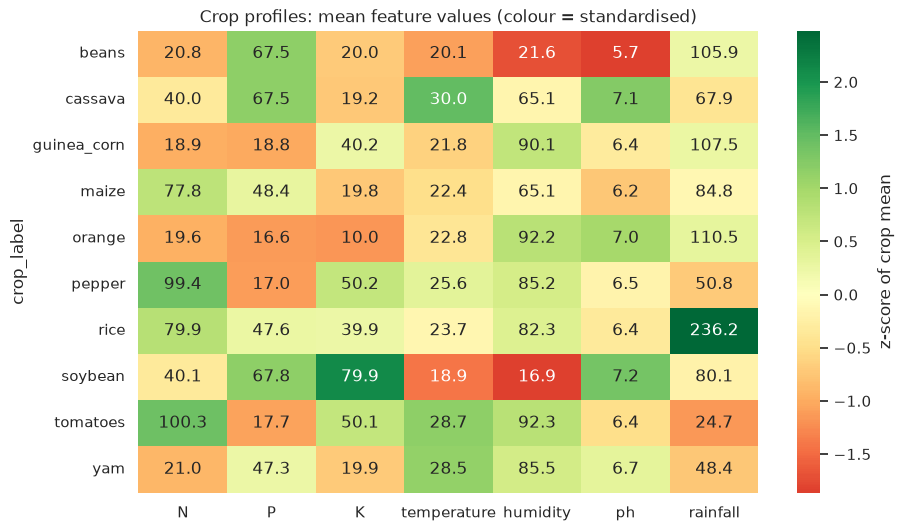

In [15]:
crop_means = df_clean.groupby(TARGET)[NUMERIC_FEATURES].mean()
display(crop_means)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap((crop_means - crop_means.mean()) / crop_means.std(), annot=crop_means.round(1), fmt="",
            cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "z-score of crop mean"})
ax.set_title("Crop profiles: mean feature values (colour = standardised)")
save_fig(fig, "06_crop_profiles")
plt.show()

### 6.3 Soil type vs crop

soil,clay,loamy,loamy clay,sandy loam
crop_label,,,,
beans,100,0,0,0
cassava,0,0,0,100
guinea_corn,0,0,0,100
maize,0,0,0,100
orange,0,100,0,0
pepper,0,0,100,0
rice,100,0,0,0
soybean,0,100,0,0
tomatoes,0,0,0,100


Chi-square = 3000.0, dof = 27, p = 0.00e+00, Cramér's V = 1.000


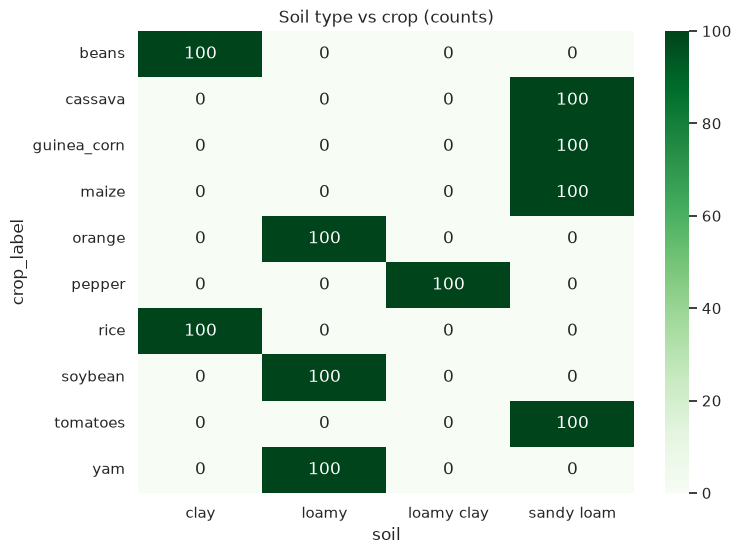

In [16]:
soil_ct = pd.crosstab(df_clean[TARGET], df_clean["soil"])
display(soil_ct)

chi2, p, dof, _ = stats.chi2_contingency(soil_ct)
cramers_v = np.sqrt(chi2 / (soil_ct.values.sum() * (min(soil_ct.shape) - 1)))
print(f"Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(soil_ct, annot=True, fmt="d", cmap="Greens", ax=ax)
ax.set_title("Soil type vs crop (counts)")
save_fig(fig, "07_soil_vs_crop")
plt.show()

**Result: soil type and crop are perfectly associated (Cramér's V = 1.0).** Every crop occurs on exactly one soil:
- clay → beans, rice
- loamy → orange, soybean, yam
- loamy clay → pepper (only)
- sandy loam → cassava, guinea_corn, maize, tomatoes

So soil alone narrows each prediction down to between 1 and 4 crops. This makes `soil` a very strong feature, but it is
also a **dataset limitation**: it almost certainly reflects how this dataset was generated rather than real agronomy,
where most crops grow on several soils. Implications, carried into later phases:
- The model will lean heavily on soil. A user entering an "unusual" soil for a crop will never see that crop recommended.
- Phase 3 will report feature importance so this dependence is visible.
- The app will state that recommendations reflect the training data's soil–crop pairings.

### 6.4 Feature relevance to the target
Two complementary scores:
- **ANOVA F-statistic:** how well a feature's *mean* differs across crops (linear separation).
- **Mutual information:** any dependency, including non-linear ones.

,anova_F,anova_p,mutual_info
rainfall,1463.11,0.00e+00,1.60
humidity,10524.11,0.00e+00,1.51
K,4667.46,0.00e+00,1.44
temperature,165.06,3.73e-190,1.02
P,862.66,0.00e+00,0.98
N,796.30,0.00e+00,0.98
ph,84.25,7.12e-116,0.59


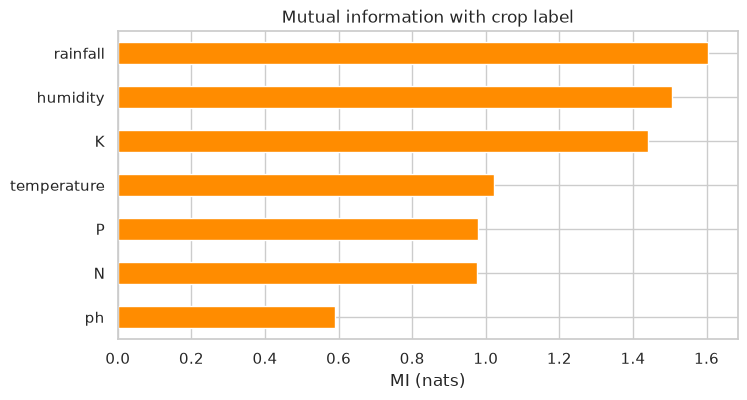

In [17]:
X_num = df_clean[NUMERIC_FEATURES]
y_raw = df_clean[TARGET]

f_stat, f_p = f_classif(X_num, y_raw)
mi = mutual_info_classif(X_num, y_raw, random_state=RANDOM_STATE)
relevance = pd.DataFrame({"anova_F": f_stat, "anova_p": f_p, "mutual_info": mi},
                         index=NUMERIC_FEATURES).sort_values("mutual_info", ascending=False)
display(relevance)

fig, ax = plt.subplots(figsize=(8, 4))
relevance["mutual_info"].plot(kind="barh", ax=ax, color="darkorange")
ax.invert_yaxis()
ax.set(title="Mutual information with crop label", xlabel="MI (nats)")
save_fig(fig, "08_mutual_information")
plt.show()

### 6.5 Pairwise view of the most informative features

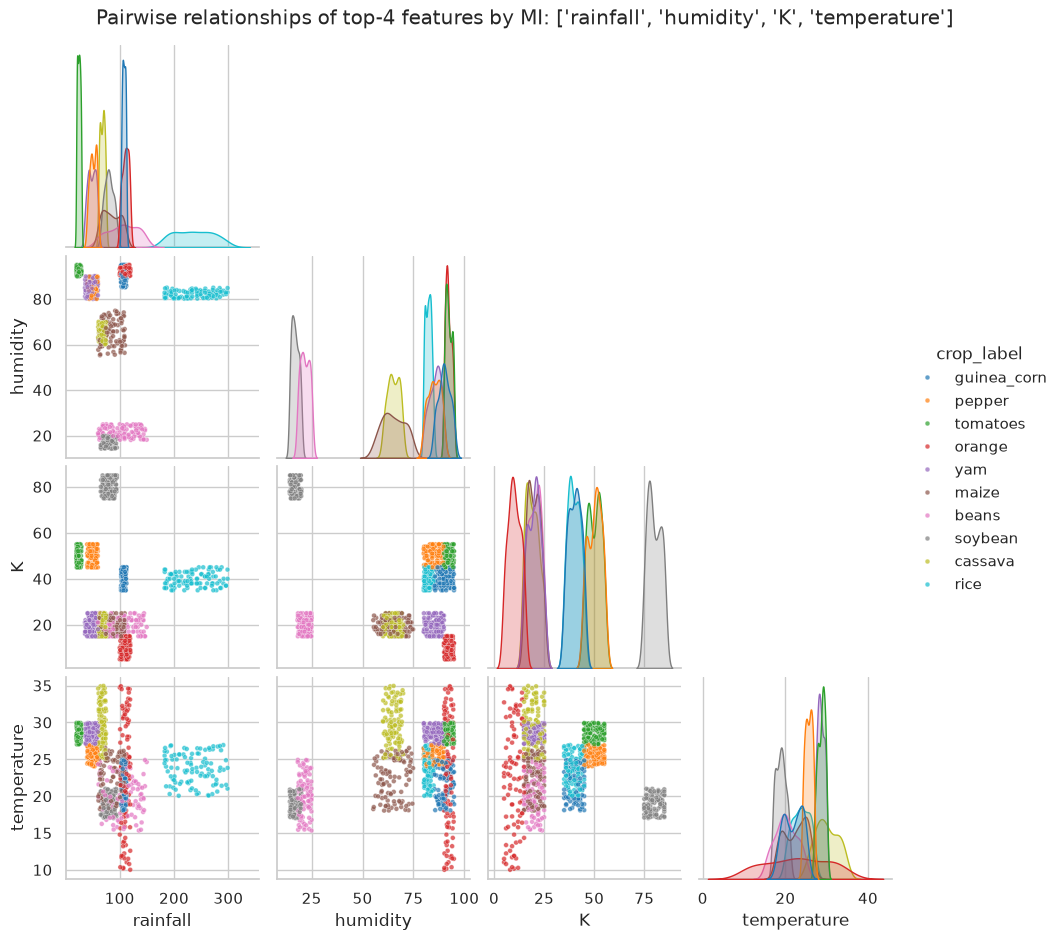

In [18]:
top_feats = relevance.index[:4].tolist()
g = sns.pairplot(df_clean, vars=top_feats, hue=TARGET, corner=True, plot_kws={"s": 12, "alpha": 0.7},
                 palette="tab10", height=2.3)
g.figure.suptitle(f"Pairwise relationships of top-4 features by MI: {top_feats}", y=1.02)
save_fig(g.figure, "09_pairplot_top_features")
plt.show()

**Takeaways:** by mutual information the ranking is rainfall (1.60) > humidity (1.51) > K (1.44) > temperature (1.02)
> P ≈ N (0.98) > pH (0.59). Every feature carries significant signal (all ANOVA p-values ≈ 0), so **all 8 inputs are
kept**. They are also exactly the inputs the app collects, which keeps the form and the report parser simple. The crop
profile heatmap (§6.2) shows that each crop has a distinctive combination of values, for example tomatoes and
pepper (high N, low P) or soybean (high K, very low humidity).

## 7. Feature engineering (candidates, evaluated, not assumed)
Candidate features with an agronomic rationale:

| Feature | Formula | Rationale |
|---|---|---|
| `npk_total` | N + P + K | Overall fertility |
| `n_p_ratio` | N / (P + 1) | Nutrient balance (the +1 avoids division by zero, since N can be 0) |
| `n_k_ratio` | N / (K + 1) | Nutrient balance |
| `p_k_ratio` | P / (K + 1) | Nutrient balance |
| `temp_humidity` | temperature × humidity / 100 | Heat–moisture interaction |

To avoid assuming they help, we compare **5-fold stratified CV macro-F1** with and without them for two quick
reference models (Logistic Regression and Random Forest). This check uses the **training split only** (from §8.1)
so the test set stays untouched. Phase 3 makes the final call on full models.

In [19]:
def add_engineered_features(data: pd.DataFrame) -> pd.DataFrame:
    # Return a copy of `data` with the candidate engineered features appended.
    out = data.copy()
    out["npk_total"] = out["N"] + out["P"] + out["K"]
    out["n_p_ratio"] = out["N"] / (out["P"] + 1)
    out["n_k_ratio"] = out["N"] / (out["K"] + 1)
    out["p_k_ratio"] = out["P"] / (out["K"] + 1)
    out["temp_humidity"] = out["temperature"] * out["humidity"] / 100
    return out

ENGINEERED_FEATURES = ["npk_total", "n_p_ratio", "n_k_ratio", "p_k_ratio", "temp_humidity"]
display(add_engineered_features(df_clean).head())

,N,P,K,temperature,humidity,ph,rainfall,soil,crop_label,npk_total,n_p_ratio,n_k_ratio,p_k_ratio,temp_humidity
0,40,27,45,21.66,94.79,5.89,112.43,sandy loam,guinea_corn,112,1.43,0.87,0.59,20.53
1,120,7,47,24.25,83.04,6.65,54.77,loamy clay,pepper,174,15.00,2.50,0.15,20.14
2,102,11,47,27.99,92.78,6.50,27.15,sandy loam,tomatoes,160,8.50,2.12,0.23,25.97
3,5,25,6,30.72,94.01,6.01,106.81,loamy,orange,36,0.19,0.71,3.57,28.88
4,36,43,21,28.36,84.86,7.14,52.93,loamy,yam,100,0.82,1.64,1.95,24.07


## 8. Preprocessing pipeline
### 8.1 Stratified train/test split (after de-duplication)
80 / 20 split, stratified by crop so each class keeps 80 train and 20 test rows. With only about 1,000
samples, Phase 3 selects models with stratified k-fold CV on the training set and touches the test set once.

In [20]:
label_encoder = LabelEncoder().fit(df_clean[TARGET])
print("Class index mapping:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

X = df_clean[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = label_encoder.transform(df_clean[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train per-class counts:", np.bincount(y_train).tolist())
print("Test per-class counts: ", np.bincount(y_test).tolist())

# Leakage check: no identical feature row may appear in both splits.
overlap = pd.merge(X_train, X_test, how="inner", on=NUMERIC_FEATURES + CATEGORICAL_FEATURES)
print("Rows shared between train and test:", len(overlap))
assert len(overlap) == 0

Class index mapping: {'beans': 0, 'cassava': 1, 'guinea_corn': 2, 'maize': 3, 'orange': 4, 'pepper': 5, 'rice': 6, 'soybean': 7, 'tomatoes': 8, 'yam': 9}
Train: (800, 8) | Test: (200, 8)
Train per-class counts: [80, 80, 80, 80, 80, 80, 80, 80, 80, 80]
Test per-class counts:  [20, 20, 20, 20, 20, 20, 20, 20, 20, 20]
Rows shared between train and test: 0


### 8.2 Preprocessor: imputation, scaling, encoding
A single `ColumnTransformer` that is **fitted on training data only** and later bundled with the model in one
scikit-learn `Pipeline` (`docs/project_overview.md` §4):

| Columns | Steps |
|---|---|
| 7 numeric | `SimpleImputer(median)` → `StandardScaler` |
| `soil` | `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown="ignore")` |
| target | `LabelEncoder` (outside the pipeline, saved with the model) |

`handle_unknown="ignore"` means an unseen soil string at inference becomes an all-zeros vector instead of
raising an error. The app will still restrict soil to the 4 known values.

In [21]:
def build_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    # Leakage-safe preprocessing: impute + scale numerics, impute + one-hot encode categoricals.
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, numeric),
        ("cat", categorical_pipe, categorical),
    ])

preprocessor = build_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)

feature_names_out = preprocessor.get_feature_names_out()
print("Transformed train shape:", Xt_train.shape, "| test shape:", Xt_test.shape)
print("Output features:", feature_names_out.tolist())

check = pd.DataFrame(Xt_train, columns=feature_names_out)
display(check.describe().T[["mean", "std", "min", "max"]])

Transformed train shape: (800, 11) | test shape: (200, 11)
Output features: ['num__N', 'num__P', 'num__K', 'num__temperature', 'num__humidity', 'num__ph', 'num__rainfall', 'cat__soil_clay', 'cat__soil_loamy', 'cat__soil_loamy clay', 'cat__soil_sandy loam']


,mean,std,min,max
num__N,-2.55e-17,1.00,-1.50,1.96
num__P,-1.24e-16,1.00,-1.63,1.71
num__K,9.66e-17,1.00,-1.47,2.45
num__temperature,-9.86e-16,1.00,-3.05,2.29
num__humidity,3.92e-16,1.00,-2.05,0.94
num__ph,-7.99e-17,1.00,-2.41,3.52
num__rainfall,7.99e-17,1.00,-1.25,3.63
cat__soil_clay,2.00e-01,0.40,0.00,1.00
cat__soil_loamy,3.00e-01,0.46,0.00,1.00
cat__soil_loamy clay,1.00e-01,0.30,0.00,1.00


Numeric columns now have mean ≈ 0 and std ≈ 1 **on the training set**. The test set is transformed with the
training statistics, so its means are close to 0 but not exactly 0, which is expected.

**Robustness check:** the fitted preprocessor should accept a row with a missing value and an unseen soil type.

In [22]:
probe = pd.DataFrame([{"N": np.nan, "P": 40, "K": 40, "temperature": 25, "humidity": 70,
                       "ph": 6.5, "rainfall": 100, "soil": "peat"}])
print(pd.DataFrame(preprocessor.transform(probe), columns=feature_names_out).round(3))

   num__N  num__P  num__K  num__temperature  num__humidity  num__ph  \
0   -0.34   -0.07    0.25              0.16           0.01    -0.12   

   num__rainfall  cat__soil_clay  cat__soil_loamy  cat__soil_loamy clay  \
0           0.15             0.0              0.0                   0.0   

   cat__soil_sandy loam  
0                   0.0  


### 8.3 Do the engineered features help? (CV on the training split only)

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reference_models = {
    "LogisticRegression": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
feature_sets = {
    "base (8 inputs)": NUMERIC_FEATURES,
    "base + engineered": NUMERIC_FEATURES + ENGINEERED_FEATURES,
}

X_train_fe = add_engineered_features(X_train)
results = []
for fs_name, num_cols in feature_sets.items():
    for model_name, model in reference_models.items():
        pipe = Pipeline([("prep", build_preprocessor(num_cols, CATEGORICAL_FEATURES)), ("model", model)])
        scores = cross_val_score(pipe, X_train_fe, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
        results.append({"feature_set": fs_name, "model": model_name,
                        "f1_macro_mean": scores.mean(), "f1_macro_std": scores.std()})

fe_results = pd.DataFrame(results).pivot(index="model", columns="feature_set",
                                         values=["f1_macro_mean", "f1_macro_std"])
display(fe_results.round(4))

f1_macro_mean                      f1_macro_std  \
feature_set        base (8 inputs) base + engineered base (8 inputs)   
model                                                                  
LogisticRegression             1.0               1.0        0.00e+00   
RandomForest                   1.0               1.0        2.50e-03   

                                      
feature_set        base + engineered  
model                                 
LogisticRegression          0.00e+00  
RandomForest                2.50e-03

In [24]:
means = pd.DataFrame(results).pivot(index="model", columns="feature_set", values="f1_macro_mean")
gain = (means["base + engineered"] - means["base (8 inputs)"])
print("Macro-F1 change from engineered features (percentage points):")
print((gain * 100).round(2))

# Decision rule: keep engineered features only if they improve CV macro-F1 by > 1 pp for BOTH models.
KEEP_ENGINEERED = bool((gain > 0.01).all())
print("\nKeep engineered features for Phase 3?", KEEP_ENGINEERED)

Macro-F1 change from engineered features (percentage points):
model
LogisticRegression    0.0
RandomForest          0.0
dtype: float64

Keep engineered features for Phase 3? False


**Result:** even plain Logistic Regression and Random Forest on the 8 base inputs reach **CV macro-F1 ≈ 1.00**.
The classes are almost perfectly separable, so the engineered features cannot add anything (gain = 0 pp) and are
**not kept**.

**What this means for Phase 3:** most candidate models will likely score at or near 100 %. Choosing on accuracy alone
won't separate them, so the **cost metrics** (latency, size, memory) and robustness will decide. The near-perfect
separability, together with the soil–crop pairing, suggests this is a clean, possibly synthetic dataset. Real-world
accuracy would be lower.

**Decision rule:** engineered features are kept only if they raise CV macro-F1 by more than 1 percentage point
for **both** reference models. Otherwise they add complexity, both in the pipeline and in what the parser must
supply, with no real gain. The flag computed above is recorded in `docs/phase_logs.md`, and Phase 3 can revisit
it on tuned models.

> The CV scores here are quick *reference* numbers, not the Phase 3 model selection.

## 9. Save outputs for Phase 3
Written to `data/processed/`, never touching the raw file:
- `crop_clean.csv`: the 1,000 de-duplicated, normalised rows.
- `train.csv` / `test.csv`: the exact stratified split used here, with the original string labels.
- `preprocessing_summary.json`: the decisions made in this notebook.

In [25]:
import json

train_out = X_train.assign(**{TARGET: label_encoder.inverse_transform(y_train)})
test_out = X_test.assign(**{TARGET: label_encoder.inverse_transform(y_test)})

df_clean.to_csv(PROCESSED_DIR / "crop_clean.csv", index=False)
train_out.to_csv(PROCESSED_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DIR / "test.csv", index=False)

summary_json = {
    "raw_rows": int(len(raw)),
    "unique_rows": int(len(df_clean)),
    "duplicates_removed": int(len(raw) - len(df_clean)),
    "label_conflicts": int((conflicts > 1).sum()),
    "missing_values": int(quality.values.sum()),
    "classes": label_encoder.classes_.tolist(),
    "rows_per_class_after_dedupe": df_clean[TARGET].value_counts().sort_index().to_dict(),
    "soil_categories": sorted(df_clean["soil"].unique().tolist()),
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "feature_ranges": {c: [float(df_clean[c].min()), float(df_clean[c].max())] for c in NUMERIC_FEATURES},
    "outlier_policy": "keep (plausible, crop-specific values); warn on out-of-range inputs at inference",
    "split": {"test_size": 0.2, "stratified": True, "random_state": RANDOM_STATE,
              "train_rows": int(len(X_train)), "test_rows": int(len(X_test))},
    "preprocessing": {"numeric": ["SimpleImputer(median)", "StandardScaler"],
                      "categorical": ["SimpleImputer(most_frequent)", "OneHotEncoder(handle_unknown=ignore)"],
                      "target": "LabelEncoder"},
    "engineered_features_evaluated": ENGINEERED_FEATURES,
    "keep_engineered_features": KEEP_ENGINEERED,
    "engineered_feature_cv_gain_pp": {k: round(float(v) * 100, 2) for k, v in gain.items()},
}
with open(PROCESSED_DIR / "preprocessing_summary.json", "w") as f:
    json.dump(summary_json, f, indent=2)

for p in sorted(PROCESSED_DIR.iterdir()):
    print(f"{p.relative_to(PROJECT_ROOT)}  ({p.stat().st_size:,} bytes)")

data/processed/crop_clean.csv  (47,460 bytes)
data/processed/preprocessing_summary.json  (1,848 bytes)
data/processed/test.csv  (9,526 bytes)
data/processed/train.csv  (37,989 bytes)


## 10. Summary of findings & decisions

| Topic | Finding | Decision |
|---|---|---|
| Schema | All 9 documented columns present; dictionary `soil_texture` = CSV `soil` | Use `soil`; alias recorded |
| Missing values | None | Imputers kept in the pipeline for safety at inference |
| Categories | `"loamy clay "` had a trailing space | Strip and lower-case all strings |
| Duplicates | 4,000 of 5,000 rows are exact duplicates; no label conflicts | De-duplicate **before** splitting (prevents leakage) |
| Class balance | Perfectly balanced after dedupe (100 per crop) | No resampling or class weights needed |
| Scales | Features range from about 5 (pH) to about 300 (rainfall) | `StandardScaler` on numerics |
| Outliers | Global IQR flags (humidity 122, rainfall 91, pH 11) but **0 within-crop outliers** | Keep; warn on out-of-range inputs in the app |
| Correlation | Max \|r\| = 0.75 (P–humidity) | No redundancy; keep all numerics |
| Soil vs crop | Perfect association (Cramér's V = 1.0); each crop on one soil | Keep `soil`; document as a dataset limitation |
| Relevance | MI: rainfall > humidity > K > temperature > P ≈ N > pH; all significant | Keep all 8 inputs |
| Separability | Reference LR / RF reach CV macro-F1 ≈ 1.00 on base inputs | Expect saturated scores in Phase 3; cost metrics decide |
| Engineered features | 0 pp gain in CV | Not kept (`keep_engineered_features = false`) |
| Encoding | 4 soil types, 10 crops | One-hot soil; label-encode target |
| Split | 80/20 stratified, seed 42, zero train/test overlap | Saved to `data/processed/` |

**Next (Phase 3, after approval):** train and compare the candidate models using these splits and this
preprocessor, on both performance and cost.